In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%config InlineBackened.format_figure = "retina"

from scipy.optimize import brute

In [2]:
import warnings
warnings.filterwarnings(action = "ignore")

In [3]:
df = pd.read_csv("forex_pairs.csv", parse_dates = ["Date"], index_col = "Date")
df.head()

,AUDEUR=X,EURUSD=X,USDGBP=X
Date,,,
2004-01-01,0.59780,1.258194,0.56016
2004-01-02,0.60314,1.258194,0.55751
2004-01-05,0.60467,1.268698,0.55334
2004-01-06,0.60350,1.272103,0.54906
2004-01-07,0.60728,1.264095,0.55012


In [4]:
df.tail()

,AUDEUR=X,EURUSD=X,USDGBP=X
Date,,,
2020-06-24,0.61349,1.131235,0.79841
2020-06-25,0.60938,1.125087,0.80561
2020-06-26,0.61373,1.122208,0.80480
2020-06-29,0.61128,1.122586,0.81023
2020-06-30,0.61097,1.124720,0.81231


In [5]:
df.columns

Index(['AUDEUR=X', 'EURUSD=X', 'USDGBP=X'], dtype='object')

In [6]:
ticker = "AUDEUR=X"

In [7]:
df = df[ticker].to_frame().dropna()
df

,AUDEUR=X
Date,
2004-01-01,0.59780
2004-01-02,0.60314
2004-01-05,0.60467
2004-01-06,0.60350
2004-01-07,0.60728
...,...
2020-06-24,0.61349
2020-06-25,0.60938
2020-06-26,0.61373


In [8]:
df = df.rename(columns = {ticker : "price"})
df

,price
Date,
2004-01-01,0.59780
2004-01-02,0.60314
2004-01-05,0.60467
2004-01-06,0.60350
2004-01-07,0.60728
...,...
2020-06-24,0.61349
2020-06-25,0.60938
2020-06-26,0.61373


In [9]:
EMA_S = 50
EMA_L = 200

In [10]:
df["EMA_S"] = df.price.ewm(span = EMA_S , min_periods = EMA_S).mean()
df["EMA_L"] = df.price.ewm(span = EMA_L , min_periods = EMA_L).mean()
df["position"] = np.where(df["EMA_S"] > df["EMA_L"] , +1 , -1)
df["trades"] = df["position"].diff().fillna(value = 0 ).abs()
df["log_ret"] = np.log(df.price/df.price.shift(1))
df["strategy"] = df["position"].shift(1) * df["log_ret"]
df["cum_log_ret"] = np.exp(df["log_ret"].cumsum())
df["cum_strategy"] = np.exp(df["strategy"].cumsum())

In [11]:
df

,price,EMA_S,EMA_L,position,trades,log_ret,strategy,cum_log_ret,cum_strategy
Date,,,,,,,,,
2004-01-01,0.59780,NaN,NaN,-1,0.0,NaN,NaN,NaN,NaN
2004-01-02,0.60314,NaN,NaN,-1,0.0,0.008893,-0.008893,1.008933,0.991146
2004-01-05,0.60467,NaN,NaN,-1,0.0,0.002533,-0.002533,1.011492,0.988638
2004-01-06,0.60350,NaN,NaN,-1,0.0,-0.001937,0.001937,1.009535,0.990555
2004-01-07,0.60728,NaN,NaN,-1,0.0,0.006244,-0.006244,1.015858,0.984389
...,...,...,...,...,...,...,...,...,...
2020-06-24,0.61349,0.601873,0.602607,-1,0.0,-0.001612,0.001612,1.026246,0.979512
2020-06-25,0.60938,0.602167,0.602674,-1,0.0,-0.006722,0.006722,1.019371,0.986118
2020-06-26,0.61373,0.602621,0.602784,-1,0.0,0.007113,-0.007113,1.026648,0.979129


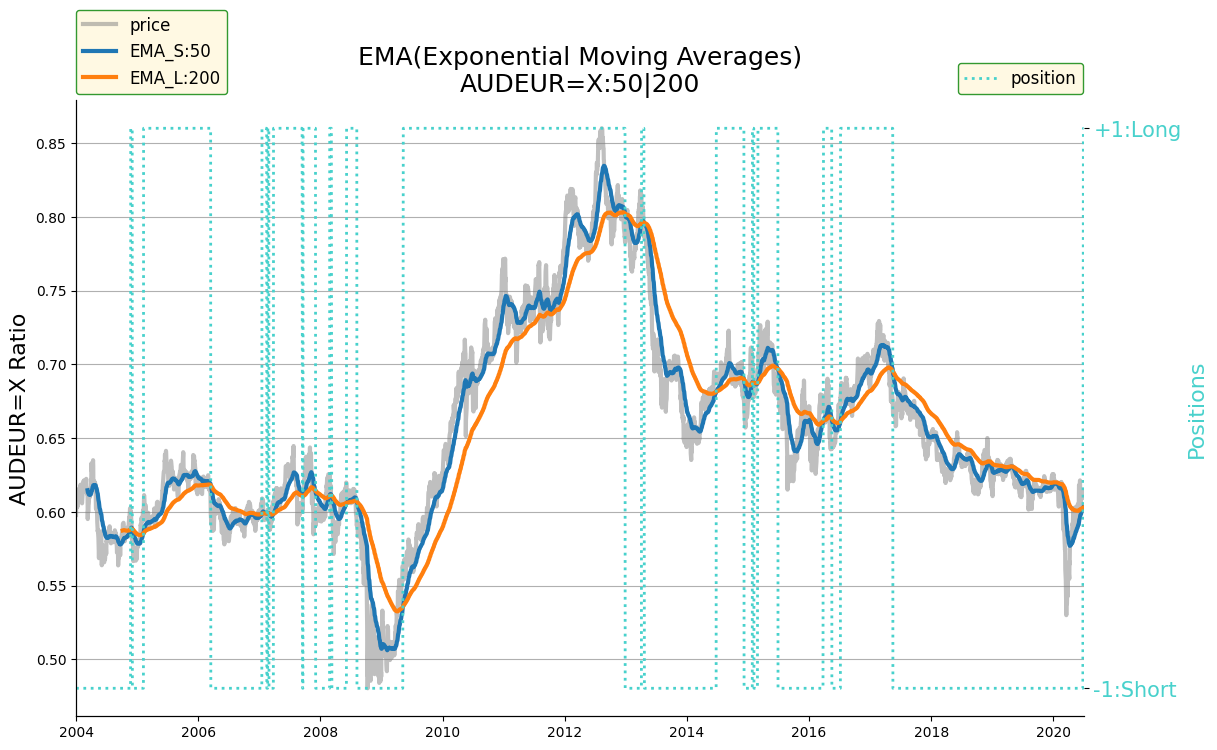

In [29]:
fig , ax = plt.subplots(1,1,figsize=(13,8))

ax.plot(df.price , label = "price" , color = "gray" , lw = 3 , alpha = 0.5)
ax.plot(df.EMA_S , label = "EMA_S:{}".format(EMA_S) , lw = 3)
ax.plot(df.EMA_L , label = "EMA_L:{}".format(EMA_L) , lw = 3)

ax.set_ylabel(f"{ticker} Ratio" , fontsize = 16)
ax.legend(fontsize = 12 ,
          loc = (0. , 1.01),
          frameon = True,
          fancybox = True,
          edgecolor = "green",
          facecolor = "cornsilk")
ax.spines[["top" , "right"]].set_visible(False)
ax.autoscale(enable=True , axis = "x" , tight=True)
ax.set_title(f"EMA(Exponential Moving Averages)\n{ticker}:{EMA_S}|{EMA_L}" , fontsize = 18)
ax.grid(axis = "y")

ax2 = ax.twinx()
ax2.plot(df.position , label = "position" , ls = ":" , color = "mediumturquoise" , lw = 2)
ax2.legend(fontsize = 12 ,
          loc = (0.875 , 1.01),
          frameon = True,
          fancybox = True,
          edgecolor = "green",
          facecolor = "cornsilk")
ax2.set_yticks([-1 , +1] , labels= ["-1:Short" , "+1:Long"] , fontsize = 15 , color = "mediumturquoise")
ax2.set_ylabel("Positions" , fontsize = 16 , color = "mediumturquoise")
ax2.spines[["top" , "right"]].set_visible(False)
ax2.autoscale(enable=True , axis = "x" , tight=True)

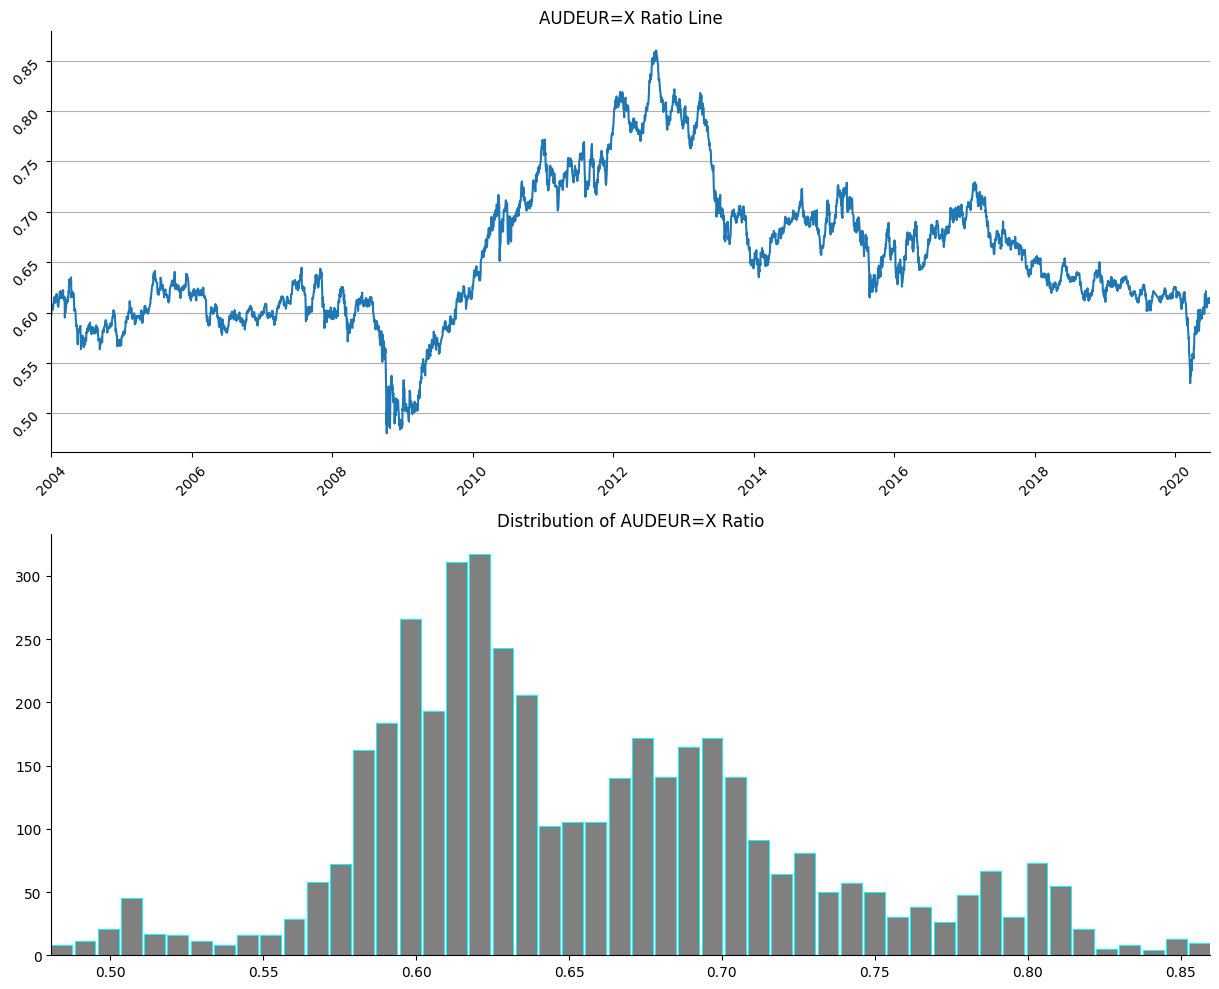

In [37]:
fig , ax = plt.subplots(figsize = (12.3,10) , ncols=1 , nrows=2)

ax[0].plot(df["price"])
ax[0].set_title(f"{ticker} Ratio Line")
ax[0].tick_params(rotation = 45)
ax[0].spines[['right','top']].set_visible(False)
ax[0].autoscale(enable = True, axis = 'x' , tight = True)
ax[0].grid(axis ="y")

ax[1].hist(df["price"] , bins = 50, rwidth = 0.9 , color = "gray" , ec="cyan" , lw = .7 )
ax[1].set_title(f"Distribution of {ticker} Ratio")
ax[1].spines[['right','top']].set_visible(False)
ax[1].autoscale(enable = True, axis = 'x' , tight = True)
plt.tight_layout()
plt.show()

In [277]:
class EMABackTester():
    '''class for the vectorized backtesting of EMA-based trading strategies:

    Attributes:
    ===========
    symbol: str
        The ticker symbol we want to trade
    EMA_S: int
        The short EMA period
    EMA_L: int
        The long EMA period
    start: str
        The start date for the backtesting period in YYYY-MM-DD format
    end: str
        The end date for the backtesting period in YYYY-MM-DD format
    pct: float
        The proportional trading cost (pct) for the backtest (e.g. 0.001 = 0.1%)

    Methods:
    ========
    get_data()
    EMA_trading_strategy(displaying_mode = None)
    plot_results()
    set_EMA_parameters(new_EMA_S = None , new_EMA_L = None)
    update_and_run_trading_strategy(EMA_tuple , displaying_mode = None)
    optimizing_trading_parameters(EMA_S_range , EMA_L_range)
    '''

    def __init__(self, symbol , EMA_S , EMA_L , start , end , pct):
        self.symbol = symbol
        self.EMA_S = EMA_S
        self.EMA_L = EMA_L
        self.start = start
        self.end = end
        self.pct  = pct
        self.data = None #Initialize data attribute
        self.get_data()


    def __repr__(self) -> str:
        rep = f"EMABackTester(symbol = {self.symbol}, EMA_S={self.EMA_S} , EMA_L={self.EMA_L} , start={self.start} , end={self.end} , pct={self.pct})"
        return rep

    def get_data(self):
        '''Load raw price data & compute initial EMAs.
        '''
        raw = pd.read_csv("forex_pairs.csv" , parse_dates=["Date"], index_col="Date")
        raw = raw[self.symbol].to_frame().dropna()
        raw = raw.loc[self.start:self.end]
        raw.columns = ["price"]
        # Calculate EMAs:
        raw["EMA_S"] = raw.price.ewm(span = self.EMA_S , min_periods = self.EMA_S).mean()
        raw["EMA_L"] = raw.price.ewm(span = self.EMA_L , min_periods = self.EMA_L).mean()

        self.data = raw
        return raw

    def EMA_trading_strategy(self , displaying_mode = None):
        '''Implement the trading strategy and displaying its performance in comparasion with the Buy&Hold Strategy result in term of value or a dataframe.
        Parameters:
        -----------
        displaying_mode : str, optional
            'tabular': Returns styled KPI table.
            'value': Returns single numeric value (final cumulative strategy return).
            None: Prints message and stores results internally.
        '''
        data = self.data.dropna().copy()
        # Generate Signals: +1 if Short EMA > Long EMA (Bullish), else -1 (Bearish/Short)
        data["position"] = np.where(data["EMA_S"] > data["EMA_L"] , +1 , -1)
        # Identify Trades: Absolute difference between consecutive positions
        data["trades"] = data["position"].diff().fillna(0).abs()
        # Log Returns of an underlying asset
        data["log_ret"] = np.log(data["price"] / data["price"].shift(1))
        # Strategy Returns: 
        # Position shifted by 1 because signal generated at close t affects return t+1
        # Subtract transaction costs (approximated linearly for simplicity)
        data["strategy"] = data["position"].shift(1) * data["log_ret"] - data["trades"] * self.pct
        data["cum_log_ret"] = np.exp(data["log_ret"].cumsum()) #Buy & Hold Value
        data["cum_strategy"] = np.exp(data["strategy"].cumsum()) #Strategy Value

        # Drop rows where calculations resulted in NaN (usually first row due to shift/diff)
        data = data.dropna()

        #Extract Final Performance Values:
        strat_perf = data["cum_strategy"].iloc[-1]
        bh_perf = data["cum_log_ret"].iloc[-1]
        out_perf = strat_perf - bh_perf

        self.KPI = pd.DataFrame(
            {
            "Absolute Performance of Strategy": strat_perf,
            "Buy&Hold_Perf": bh_perf,
            "Out_Performance": out_perf,
            "Ann. Return Buy&Hold": data["log_ret"].mean() * 252,
            "Ann. Risk Buy&Hold": data["log_ret"].std() * np.sqrt(252),
            "Ann. Return_Strategy": data["strategy"].mean() * 252,
            "Ann. Risk_Strategy": data["strategy"].std() * np.sqrt(252)
            }, 
        index=["results {} | {}".format(self.EMA_S, self.EMA_L)]
        )

        # Style formatting for tabular view
        self.KPI_table = self.KPI.T.style.format("{:.2%}")


        #self.KPI_values = self.KPI.T
        self.results = data
        
        if displaying_mode == "tabular":
            return self.KPI_table
        elif displaying_mode == "value":
            # Return just the final cumulative strategy value as a float for optimizer
            return float(strat_perf)
        else:
            print("Display mode not specified. Results stored in .results and .KPI")
            return None
         
    def plot_results(self):
        '''Plot Strategy vs Buy & Hold equity curves.
        '''
        if self.results is None or self.results.empty:
            print("There is nothing to display! Run EMA_trading_strategy() first.")
        else:        
            self.results.dropna().iloc[:,-2:].plot(figsize = (14,8))
            plt.title(f"Strategy VS Buy& Hold\n {self.symbol}: {self.EMA_S} | {self.EMA_L}" , fontsize = 18)
            plt.ylabel("Value")
            plt.xlabel("Date")
            plt.autoscale(enable = True , axis ="x" , tight = True)
            plt.gca().spines[["top","right"]].set_visible(False)
            plt.legend(labels = ["Buy & Hold" , "Strategy"] , fontsize = 12 , loc = (.8,1.01) , fancybox = True , frameon = True , facecolor = "cornsilk" , shadow = True)
            plt.grid(axis = "y")
            plt.show()

    def set_EMA_parameters(self , new_EMA_S = None , new_EMA_L = None):
        '''Update new EMA parameters for both of EMA_S and EMA_L and recalculate EMAs on existing data.
        '''
        raw = self.data[["price"]].copy()

        if new_EMA_S is not None:
            self.EMA_S = int(new_EMA_S)
            raw["EMA_S"] = raw.price.ewm(span = self.EMA_S , min_periods = self.EMA_S).mean()
        if new_EMA_L is not None:
            self.EMA_L = int(new_EMA_L)
            raw["EMA_L"] = raw.price.ewm(span = self.EMA_L , min_periods = self.EMA_L).mean()

        self.data = raw

    def update_and_run_trading_strategy(self , EMA_params:tuple , displaying_mode =None):
        '''Update our trading strategy with a new set of parameters of EMA:(EMA_S , EMA_L). 
        displaying_mode = 'tabular' or 'value'
        It will be used to find the final optimal value by using the `brute()` function from scipy.optimize.
        '''
        self.set_EMA_parameters(int(EMA_params[0]) , int(EMA_params[1]))
        return self.EMA_trading_strategy(displaying_mode=displaying_mode)

    def optimizing_trading_parameter(self ,EMA_S_tuple:tuple , EMA_L_tuple:tuple):
        '''
        Optimize  EMA_S & EMA_L parameters using grid search (brute force).
        Parameters:
        -----------
        ema_s_range: tuple
            (start , stop , step) for Short EMA
        ema_l_range: tuple
            (start , stop , step) for Long EMA
        
        Returns:
        --------
        best_params : ndarray
            Array containing [best_EMA_S , best_EMA_L]
        best_result : DataFrame/Style
        It computes the argmin of the trading strategy within a range of values for EMA_S & EMA_L.
        and compute the minimum value of  -1 * objective function which is equivalent to the maximium of the objective function.
        (EMA_S:(start = 10 , stop = 50 , step = 1) , EMA_L:(start = 100 , stop = 252 , step = 1))
        '''
        ranges = (EMA_S_tuple , EMA_L_tuple)
        obj_func = lambda x : -1*self.update_and_run_trading_strategy((x[0],x[1]) , displaying_mode="value")
        optimized_value = brute(obj_func , ranges)
        best_ema_s , best_ema_l = int(optimized_value[0]) , int(optimized_value[1])
        print(f"Optimal Parameters Found: EMA_S={best_ema_s} , EMA_L={best_ema_l}")
        final_KPI = self.update_and_run_trading_strategy(optimized_value , displaying_mode="tabular")
        return (best_ema_s , best_ema_l) , final_KPI

In [288]:
symbol = "EURUSD=X"

In [289]:
ematester = EMABackTester(symbol = symbol , EMA_S = 50 , EMA_L=200 , start="2004-01-01" , end="2020-06-30" , pct = 0.00007)

In [290]:
ematester.symbol

'EURUSD=X'

In [291]:
ematester.EMA_S , ematester.EMA_L

(50, 200)

In [292]:
ematester.start , ematester.end

('2004-01-01', '2020-06-30')

In [293]:
ematester.pct

7e-05

In [294]:
ematester.EMA_trading_strategy(displaying_mode="tabular")

,results 50 | 200
Absolute Performance of Strategy,127.24%
Buy&Hold_Perf,91.58%
Out_Performance,35.66%
Ann. Return Buy&Hold,-0.54%
Ann. Risk Buy&Hold,12.08%
Ann. Return_Strategy,1.49%
Ann. Risk_Strategy,12.08%


In [295]:
ematester.EMA_trading_strategy(displaying_mode="value")

1.272404514229137

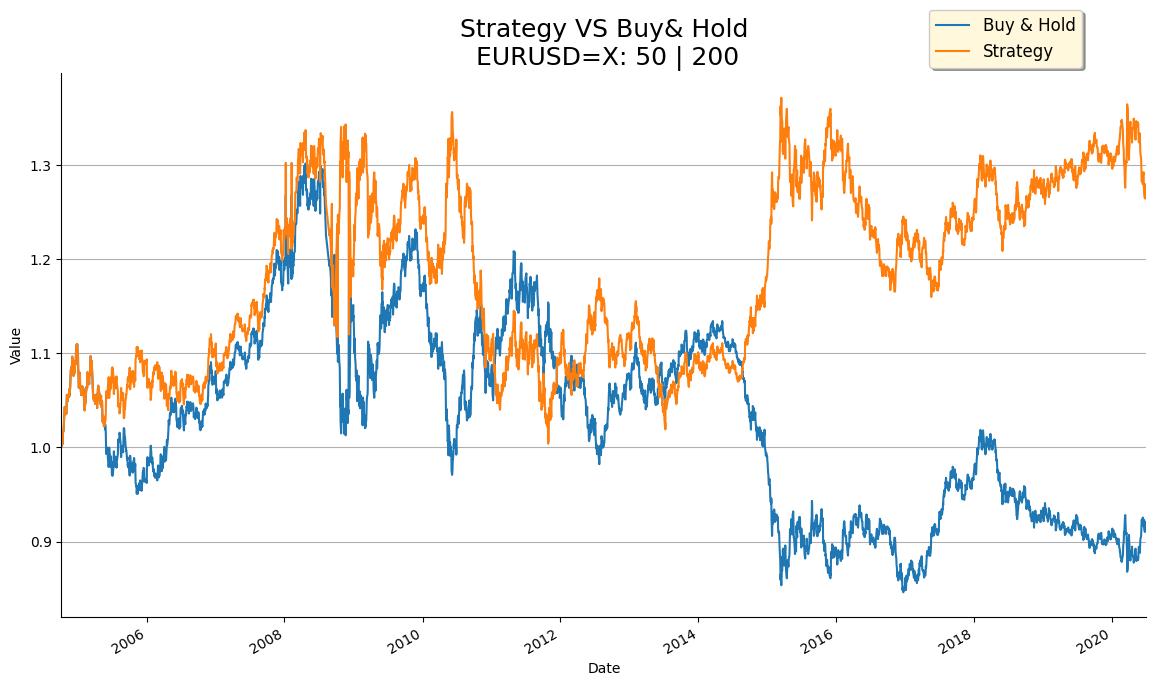

In [296]:
ematester.plot_results()

In [299]:
ematester.EMA_trading_strategy(displaying_mode="tabular")

,results 40 | 200
Absolute Performance of Strategy,108.72%
Buy&Hold_Perf,91.58%
Out_Performance,17.14%
Ann. Return Buy&Hold,-0.54%
Ann. Risk Buy&Hold,12.08%
Ann. Return_Strategy,0.52%
Ann. Risk_Strategy,12.08%


In [300]:
ematester.optimizing_trading_parameter((10,52,1),(100,252,1))

Optimal Parameters Found: EMA_S=36 , EMA_L=168


((36, 168), <pandas.io.formats.style.Styler at 0x2198680de50>)

In [301]:
ematester.update_and_run_trading_strategy(EMA_params= (36, 168) , displaying_mode='tabular')

,results 36 | 168
Absolute Performance of Strategy,166.16%
Buy&Hold_Perf,92.55%
Out_Performance,73.61%
Ann. Return Buy&Hold,-0.47%
Ann. Risk Buy&Hold,12.05%
Ann. Return_Strategy,3.12%
Ann. Risk_Strategy,12.05%


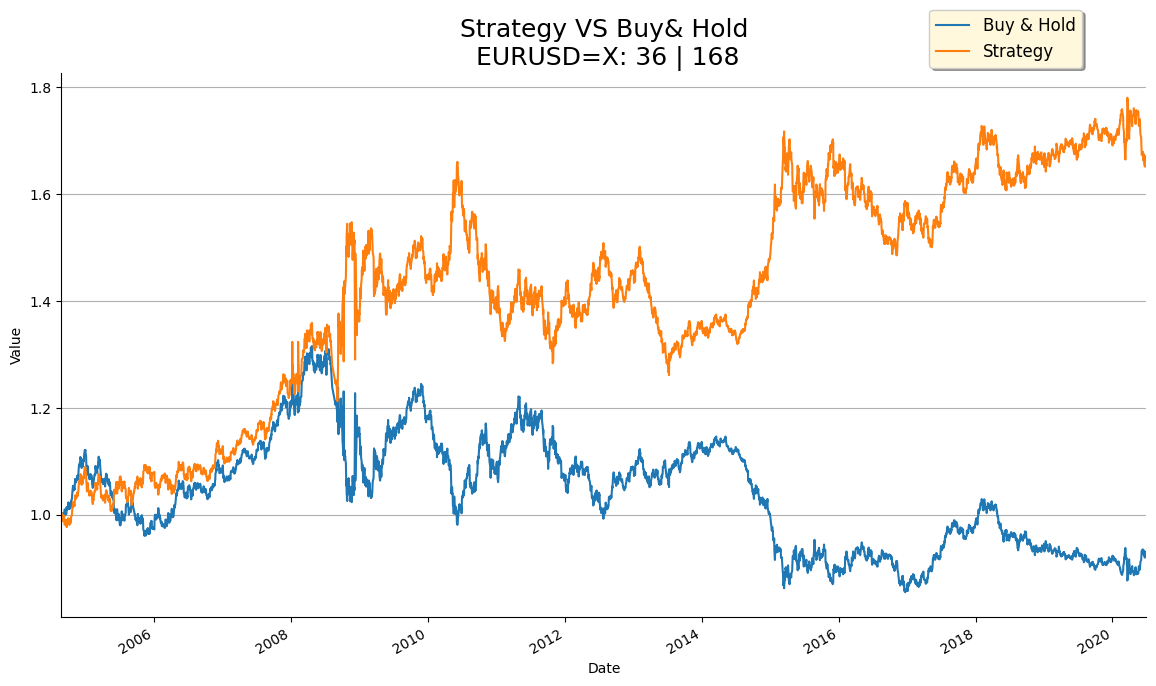

In [302]:
ematester.plot_results()